In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv("../data/vendas.csv")

df.head()

,id_venda,data,cliente,produto,categoria,regiao,quantidade,preco_unitario,desconto,receita,vendedor
0,4872,2025-01-01,Cliente 043,Pallet PBR,Pallets,Recife,39,46.36,0.00,1808.04,Carla
1,3155,2025-01-01,Cliente 010,Pallet PBR,Pallets,Olinda,38,47.69,0.00,1812.22,Diego
2,2967,2025-01-01,Cliente 085,Pallet PBR,Pallets,Olinda,48,42.69,0.03,1987.65,Eduardo
3,4567,2025-01-01,Cliente 057,Caixa Plástica,Embalagens,Recife,48,27.38,0.10,1182.82,Diego
4,100,2025-01-01,Cliente 008,Pallet Industrial,Pallets,Paulista,28,83.10,0.03,2257.00,Bruno


In [6]:
df["data"] = pd.to_datetime(df["data"])

In [7]:
print("Data inicial:", df["data"].min())
print("Data final:", df["data"].max())

Data inicial: 2025-01-01 00:00:00
Data final: 2026-08-30 00:00:00


In [8]:
vendas_mensais = (
    df.groupby(df["data"].dt.to_period("M"))["quantidade"]
    .sum()
)

vendas_mensais

data
2025-01    8282
2025-02    7858
2025-03    8022
2025-04    8823
2025-05    9761
2025-06    8590
2025-07    8747
2025-08    8603
2025-09    9461
2025-10    8331
2025-11    8347
2025-12    8508
2026-01    9101
2026-02    8565
2026-03    9770
2026-04    8572
2026-05    8947
2026-06    8431
2026-07    9422
2026-08    9035
Freq: M, Name: quantidade, dtype: int64

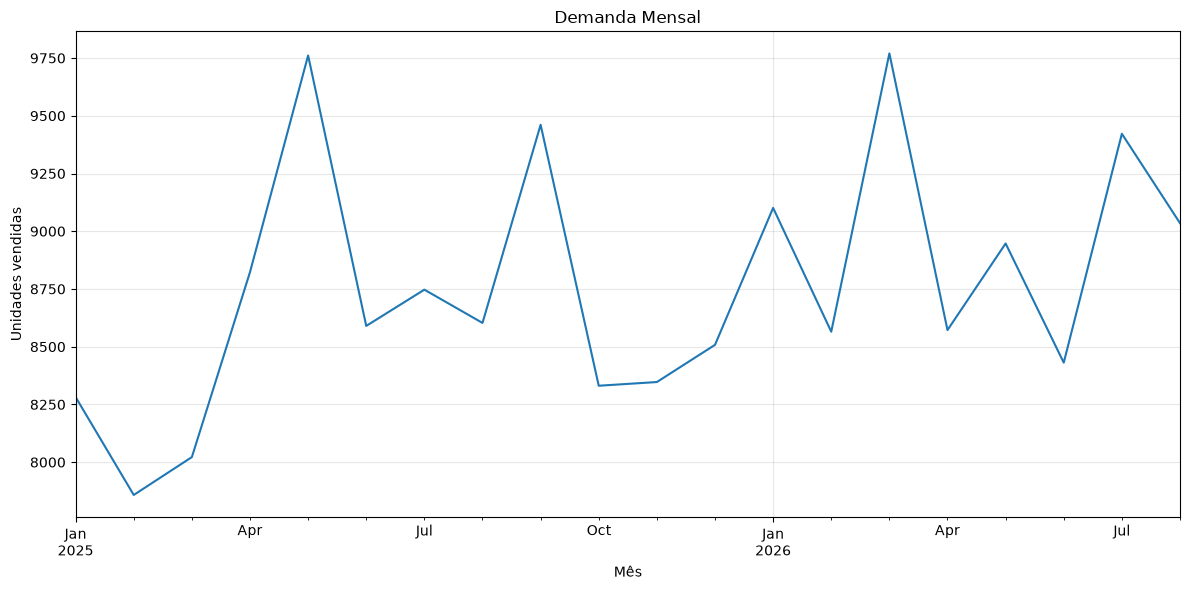

In [9]:
vendas_mensais.index = vendas_mensais.index.to_timestamp()

vendas_mensais.plot(figsize=(12, 6))

plt.title("Demanda Mensal")
plt.xlabel("Mês")
plt.ylabel("Unidades vendidas")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
dados = vendas_mensais.to_frame(name="quantidade")

dados["mes"] = dados.index.month
dados["ano"] = dados.index.year

dados

,quantidade,mes,ano
data,,,
2025-01-01,8282,1,2025
2025-02-01,7858,2,2025
2025-03-01,8022,3,2025
2025-04-01,8823,4,2025
2025-05-01,9761,5,2025
2025-06-01,8590,6,2025
2025-07-01,8747,7,2025
2025-08-01,8603,8,2025
2025-09-01,9461,9,2025


In [11]:
dados["mes_anterior"] = dados["quantidade"].shift(1)

dados

,quantidade,mes,ano,mes_anterior
data,,,,
2025-01-01,8282,1,2025,NaN
2025-02-01,7858,2,2025,8282.0
2025-03-01,8022,3,2025,7858.0
2025-04-01,8823,4,2025,8022.0
2025-05-01,9761,5,2025,8823.0
2025-06-01,8590,6,2025,9761.0
2025-07-01,8747,7,2025,8590.0
2025-08-01,8603,8,2025,8747.0
2025-09-01,9461,9,2025,8603.0


In [12]:
dados = dados.dropna()

dados

,quantidade,mes,ano,mes_anterior
data,,,,
2025-02-01,7858,2,2025,8282.0
2025-03-01,8022,3,2025,7858.0
2025-04-01,8823,4,2025,8022.0
2025-05-01,9761,5,2025,8823.0
2025-06-01,8590,6,2025,9761.0
2025-07-01,8747,7,2025,8590.0
2025-08-01,8603,8,2025,8747.0
2025-09-01,9461,9,2025,8603.0
2025-10-01,8331,10,2025,9461.0


In [13]:
treino = dados.iloc[:-4]
teste = dados.iloc[-4:]

print("Treino:")
print(treino)

print("\nTeste:")
print(teste)

Treino:
            quantidade  mes   ano  mes_anterior
data                                           
2025-02-01        7858    2  2025        8282.0
2025-03-01        8022    3  2025        7858.0
2025-04-01        8823    4  2025        8022.0
2025-05-01        9761    5  2025        8823.0
2025-06-01        8590    6  2025        9761.0
2025-07-01        8747    7  2025        8590.0
2025-08-01        8603    8  2025        8747.0
2025-09-01        9461    9  2025        8603.0
2025-10-01        8331   10  2025        9461.0
2025-11-01        8347   11  2025        8331.0
2025-12-01        8508   12  2025        8347.0
2026-01-01        9101    1  2026        8508.0
2026-02-01        8565    2  2026        9101.0
2026-03-01        9770    3  2026        8565.0
2026-04-01        8572    4  2026        9770.0

Teste:
            quantidade  mes   ano  mes_anterior
data                                           
2026-05-01        8947    5  2026        8572.0
2026-06-01        8431  

In [14]:
X_treino = treino[["mes", "ano", "mes_anterior"]]
y_treino = treino["quantidade"]

X_teste = teste[["mes", "ano", "mes_anterior"]]
y_teste = teste["quantidade"]

print("X treino:")
print(X_treino)

print("\ny treino:")
print(y_treino)

X treino:
            mes   ano  mes_anterior
data                               
2025-02-01    2  2025        8282.0
2025-03-01    3  2025        7858.0
2025-04-01    4  2025        8022.0
2025-05-01    5  2025        8823.0
2025-06-01    6  2025        9761.0
2025-07-01    7  2025        8590.0
2025-08-01    8  2025        8747.0
2025-09-01    9  2025        8603.0
2025-10-01   10  2025        9461.0
2025-11-01   11  2025        8331.0
2025-12-01   12  2025        8347.0
2026-01-01    1  2026        8508.0
2026-02-01    2  2026        9101.0
2026-03-01    3  2026        8565.0
2026-04-01    4  2026        9770.0

y treino:
data
2025-02-01    7858
2025-03-01    8022
2025-04-01    8823
2025-05-01    9761
2025-06-01    8590
2025-07-01    8747
2025-08-01    8603
2025-09-01    9461
2025-10-01    8331
2025-11-01    8347
2025-12-01    8508
2026-01-01    9101
2026-02-01    8565
2026-03-01    9770
2026-04-01    8572
Freq: MS, Name: quantidade, dtype: int64


In [15]:
from sklearn.ensemble import RandomForestRegressor

modelo = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

modelo.fit(X_treino, y_treino)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [16]:
previsoes = modelo.predict(X_teste)

previsoes

array([9536.72, 9205.41, 8957.48, 8672.6 ])

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_teste, previsoes)
rmse = np.sqrt(mean_squared_error(y_teste, previsoes))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 547.76
RMSE: 568.9


In [18]:
comparacao = pd.DataFrame({
    "real": y_teste.values,
    "previsao": previsoes
}, index=y_teste.index)

comparacao

,real,previsao
data,,
2026-05-01,8947,9536.72
2026-06-01,8431,9205.41
2026-07-01,9422,8957.48
2026-08-01,9035,8672.60


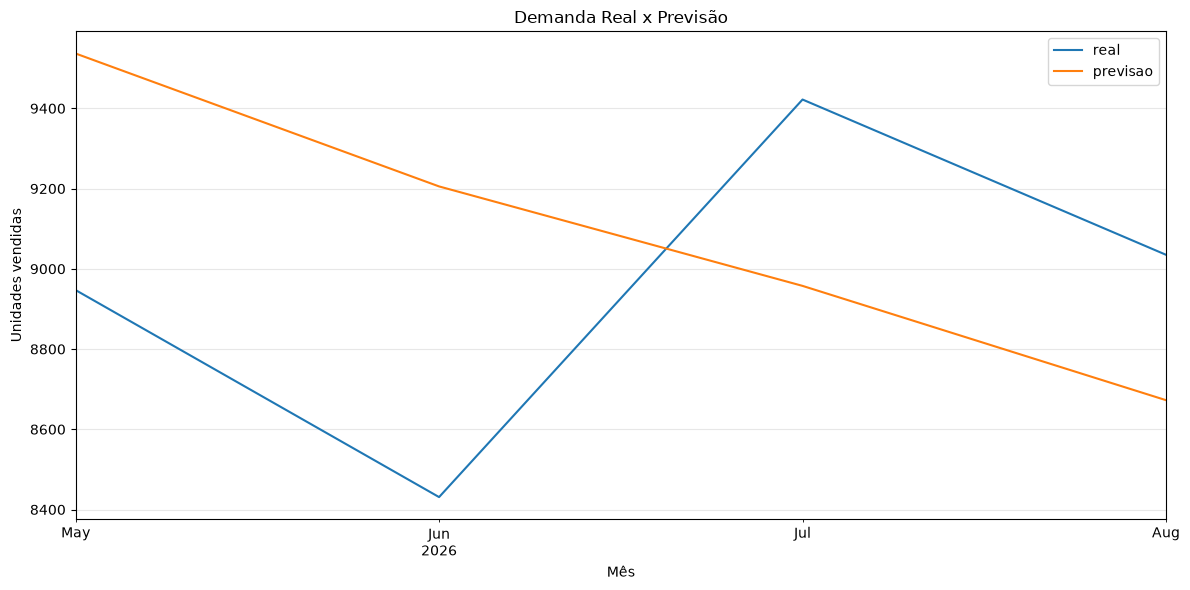

In [19]:
comparacao.plot(figsize=(12, 6))

plt.title("Demanda Real x Previsão")
plt.xlabel("Mês")
plt.ylabel("Unidades vendidas")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
previsao_baseline = teste["mes_anterior"]

mae_baseline = mean_absolute_error(
    y_teste,
    previsao_baseline
)

print("MAE do baseline:", round(mae_baseline, 2))
print("MAE do Random Forest:", round(mae, 2))

MAE do baseline: 567.25
MAE do Random Forest: 547.76


In [21]:
proximo_mes = pd.DataFrame({
    "mes": [9],
    "ano": [2026],
    "mes_anterior": [9035]
})

previsao_setembro = modelo.predict(proximo_mes)

print(
    "Previsão de demanda para setembro de 2026:",
    round(previsao_setembro[0])
)

Previsão de demanda para setembro de 2026: 8879
